0. library

In [1]:
# ============================================================
# 0. LIBRARY
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, spearmanr

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import KNNImputer
from sklearn.preprocessing import PowerTransformer
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression

from statsmodels.stats.outliers_influence import variance_inflation_factor

from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings("ignore")


0.1 upload dataset

In [2]:
import pandas as pd

file_path = "online_retail_II.csv"

df = pd.read_csv(file_path, encoding="latin1")

print("Dataset berhasil dibaca!")
print("Ukuran dataset:", df.shape)

Dataset berhasil dibaca!
Ukuran dataset: (541910, 8)


1. DATA LEAKAGE

In [3]:
# ============================================================
# 1. DATA LEAKAGE
# Algoritma: PIPELINE
# ============================================================

data = df[["Quantity", "Price"]].dropna().copy()

X = data[["Quantity"]]
y = data["Price"]

# Membagi data terlebih dahulu
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Pipeline
model = Pipeline([
    ("transform", PowerTransformer(method="yeo-johnson")),
    ("model", LinearRegression())
])

# Training hanya menggunakan data train
model.fit(X_train, y_train)

score = model.score(X_test, y_test)

print("DATA LEAKAGE")
print("Data Train :", len(X_train))
print("Data Test  :", len(X_test))
print("R2 Score   :", score)

DATA LEAKAGE
Data Train : 433528
Data Test  : 108382
R2 Score   : -7.321815059579961e-06


2. Scaling Data Skewed

Skewness sebelum Yeo-Johnson : 4.080924750023666
Skewness sesudah Yeo-Johnson : -0.19450463834673198


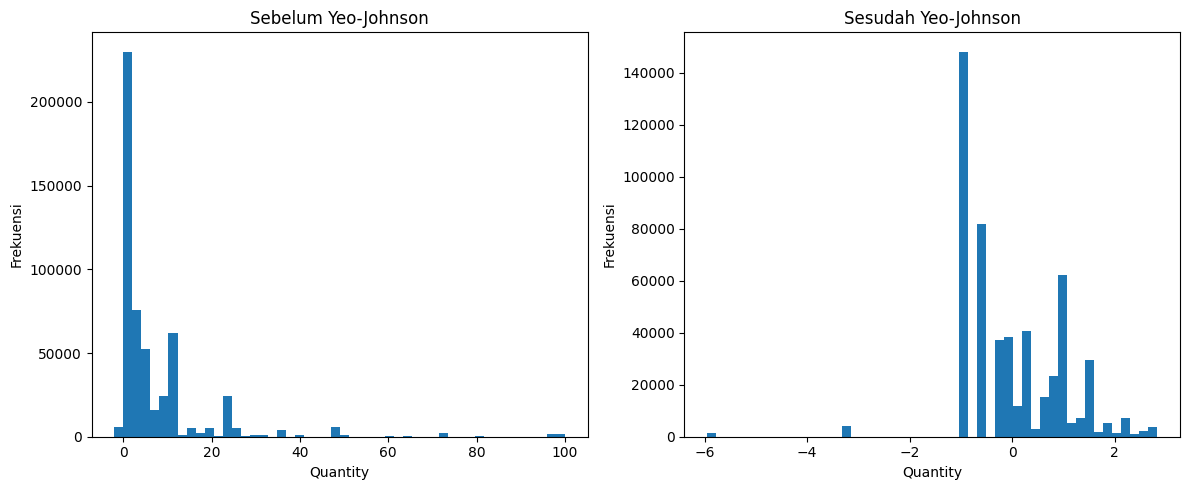

In [4]:
# ============================================================
# 2. SCALING DATA SKEWED - YEO-JOHNSON
# ============================================================

from sklearn.preprocessing import PowerTransformer
from scipy.stats import skew
import numpy as np
import matplotlib.pyplot as plt

# Ambil data Quantity
quantity = df[["Quantity"]].dropna().copy()

# Batasi nilai ekstrem untuk proses transformasi
# agar nilai ekstrem tidak mendominasi transformasi
Q1 = quantity["Quantity"].quantile(0.01)
Q99 = quantity["Quantity"].quantile(0.99)

quantity_filtered = quantity[
    (quantity["Quantity"] >= Q1) &
    (quantity["Quantity"] <= Q99)
]

# Skewness sebelum
skew_before = skew(quantity_filtered["Quantity"])

# Yeo-Johnson
pt = PowerTransformer(method="yeo-johnson")

quantity_transformed = pt.fit_transform(
    quantity_filtered[["Quantity"]]
)

# Skewness sesudah
skew_after = skew(quantity_transformed[:, 0])

print("Skewness sebelum Yeo-Johnson :", skew_before)
print("Skewness sesudah Yeo-Johnson :", skew_after)

# Visualisasi
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(quantity_filtered["Quantity"], bins=50)
plt.title("Sebelum Yeo-Johnson")
plt.xlabel("Quantity")
plt.ylabel("Frekuensi")

plt.subplot(1, 2, 2)
plt.hist(quantity_transformed[:, 0], bins=50)
plt.title("Sesudah Yeo-Johnson")
plt.xlabel("Quantity")
plt.ylabel("Frekuensi")

plt.tight_layout()
plt.show()

3. Missing Value 

In [5]:
# ============================================================
# CELL 3 - MISSING VALUE
# Algoritma: KNN Imputer
# ============================================================

# Pilih fitur numerik
data_knn = df[
    ["Customer ID", "Quantity", "Price"]
].copy()

# Gunakan maksimal 10.000 data
data_knn_sample = data_knn.sample(
    n=min(10000, len(data_knn)),
    random_state=42
)

print("Jumlah data yang digunakan :", len(data_knn_sample))

# Missing value sebelum
print("\nMissing value SEBELUM:")
print(data_knn_sample.isnull().sum())

# KNN Imputer
imputer = KNNImputer(
    n_neighbors=5
)

data_imputed = imputer.fit_transform(
    data_knn_sample
)

# Jadikan DataFrame
data_imputed = pd.DataFrame(
    data_imputed,
    columns=data_knn_sample.columns,
    index=data_knn_sample.index
)

# Missing value sesudah
print("\nMissing value SESUDAH:")
print(data_imputed.isnull().sum())

print("\nContoh hasil:")
display(data_imputed.head(10))

Jumlah data yang digunakan : 10000

Missing value SEBELUM:
Customer ID    2510
Quantity          0
Price             0
dtype: int64

Missing value SESUDAH:
Customer ID    0
Quantity       0
Price          0
dtype: int64

Contoh hasil:


,Customer ID,Quantity,Price
209270,14606.0,1.0,2.95
207110,14031.0,30.0,3.95
507583,15418.8,13.0,1.63
429176,15974.0,2.0,4.95
115865,13502.0,2.0,9.95
455415,15463.0,4.0,3.95
525711,14649.0,12.0,0.42
367857,16653.0,25.0,0.42
156241,15849.8,1.0,2.95
259824,14267.0,-12.0,3.75


4.	Multikolinearitas

In [13]:
# ============================================================
# CELL 4 - MULTIKOLINEARITAS
# Algoritma: VIF
# ============================================================

# Buat Revenue
data_vif = df[
    ["Quantity", "Price"]
].dropna().copy()

data_vif["Revenue"] = (
    data_vif["Quantity"] *
    data_vif["Price"]
)

# Ambil sampel agar lebih ringan
data_vif = data_vif.sample(
    n=min(10000, len(data_vif)),
    random_state=42
)

fitur = [
    "Quantity",
    "Price",
    "Revenue"
]

X_vif = data_vif[fitur]

# Hitung VIF
hasil_vif = pd.DataFrame()

hasil_vif["Fitur"] = X_vif.columns

hasil_vif["VIF"] = [
    variance_inflation_factor(
        X_vif.values,
        i
    )
    for i in range(X_vif.shape[1])
]

print("Hasil VIF:")
display(hasil_vif)

print("\nInterpretasi umum:")
print("VIF sekitar 1      = rendah")
print("VIF 1 - 5          = relatif aman")
print("VIF > 5             = perlu diperhatikan")
print("VIF > 10            = multikolinearitas tinggi")

Hasil VIF:


,Fitur,VIF
0,Quantity,1.280938
1,Price,1.564771
2,Revenue,1.852022



Interpretasi umum:
VIF sekitar 1      = rendah
VIF 1 - 5          = relatif aman
VIF > 5             = perlu diperhatikan
VIF > 10            = multikolinearitas tinggi


Cell 5 — Class Imbalance

In [6]:
# ============================================================
# 5. CLASS IMBALANCE
# Algoritma: SMOTE
# ============================================================

data_rfm = df.copy()

# Revenue
data_rfm["Revenue"] = (
    data_rfm["Quantity"] *
    data_rfm["Price"]
)

# Agregasi per Customer
customer = data_rfm.groupby(
    "Customer ID"
).agg(
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum")
).dropna()

# Membuat target
batas = customer["Monetary"].quantile(0.90)

customer["Target"] = (
    customer["Monetary"] >= batas
).astype(int)

print("Distribusi kelas sebelum SMOTE:")
print(customer["Target"].value_counts())

# Fitur
X = customer[[
    "Frequency"
]]

y = customer["Target"]

# Train-test split stratified
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# SMOTE
smote = SMOTE(
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("\nDistribusi kelas setelah SMOTE:")
print(y_train_smote.value_counts())

Distribusi kelas sebelum SMOTE:
Target
0    3934
1     438
Name: count, dtype: int64

Distribusi kelas setelah SMOTE:
Target
0    3147
1    3147
Name: count, dtype: int64


Cell 6 — Hubungan Non-Linear

Jumlah data yang dianalisis : 10000
Spearman Correlation        : -0.3722807837886205
P-value                     : 0.0


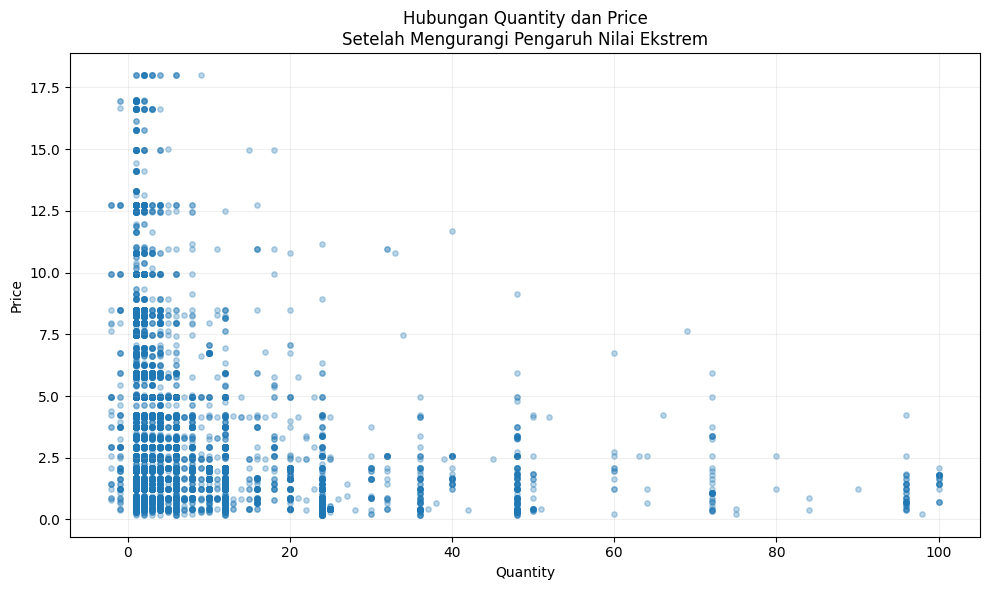

In [12]:
# ============================================================
# CELL 6 - HUBUNGAN NON-LINEAR
# Algoritma: Spearman Correlation
# ============================================================

from scipy.stats import spearmanr
import matplotlib.pyplot as plt

# Ambil data
data_spearman = df[
    ["Quantity", "Price"]
].dropna().copy()

# Hilangkan Price negatif untuk analisis harga
data_spearman = data_spearman[
    data_spearman["Price"] >= 0
]

# Tentukan batas 1% dan 99%
q1_quantity = data_spearman["Quantity"].quantile(0.01)
q99_quantity = data_spearman["Quantity"].quantile(0.99)

q1_price = data_spearman["Price"].quantile(0.01)
q99_price = data_spearman["Price"].quantile(0.99)

# Batasi data untuk analisis dan visualisasi
data_filtered = data_spearman[
    (data_spearman["Quantity"] >= q1_quantity) &
    (data_spearman["Quantity"] <= q99_quantity) &
    (data_spearman["Price"] >= q1_price) &
    (data_spearman["Price"] <= q99_price)
]

# Ambil sampel agar grafik tidak terlalu padat
data_filtered = data_filtered.sample(
    n=min(10000, len(data_filtered)),
    random_state=42
)

# ============================================================
# SPEARMAN CORRELATION
# ============================================================

korelasi, p_value = spearmanr(
    data_filtered["Quantity"],
    data_filtered["Price"]
)

print("Jumlah data yang dianalisis :", len(data_filtered))
print("Spearman Correlation        :", korelasi)
print("P-value                     :", p_value)

# ============================================================
# VISUALISASI
# ============================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    data_filtered["Quantity"],
    data_filtered["Price"],
    alpha=0.3,
    s=15
)

plt.title(
    "Hubungan Quantity dan Price\n"
    "Setelah Mengurangi Pengaruh Nilai Ekstrem"
)

plt.xlabel("Quantity")
plt.ylabel("Price")

plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Cell 7 — ID Unik

In [8]:
# ============================================================
# 7. ID UNIK SEBAGAI FITUR
# Algoritma: FEATURE AGGREGATION
# ============================================================

# Customer ID tidak digunakan langsung sebagai angka.
# Customer ID digunakan untuk membuat fitur baru.

customer_features = df.groupby(
    "Customer ID"
).agg(
    Jumlah_Transaksi=("Invoice", "nunique"),
    Jumlah_Produk=("StockCode", "nunique"),
    Total_Quantity=("Quantity", "sum"),
    Total_Pembelian=("Price", "sum")
).reset_index()

print("Hasil Feature Aggregation:")
display(customer_features.head(10))

Hasil Feature Aggregation:


,Customer ID,Jumlah_Transaksi,Jumlah_Produk,Total_Quantity,Total_Pembelian
0,12346.0,2,1,0,2.08
1,12347.0,7,103,2458,481.21
2,12348.0,4,22,2341,178.71
3,12349.0,1,73,631,605.10
4,12350.0,1,17,197,65.30
5,12352.0,11,59,470,2211.10
6,12353.0,1,4,20,24.30
7,12354.0,1,58,530,261.22
8,12355.0,1,13,240,54.65
9,12356.0,3,53,1591,188.87


Cell 8 — Masking Effect

In [9]:
# ============================================================
# 8. MASKING EFFECT
# Algoritma: MODIFIED Z-SCORE
# ============================================================

quantity = df[
    "Quantity"
].dropna()

# Median
median = quantity.median()

# MAD
MAD = np.median(
    np.abs(quantity - median)
)

# Modified Z-Score
modified_z = (
    0.6745 *
    (quantity - median) /
    MAD
)

# Deteksi outlier
outlier = quantity[
    np.abs(modified_z) > 3.5
]

print(
    "Jumlah outlier berdasarkan Modified Z-Score:",
    len(outlier)
)

print("\nContoh outlier:")
print(outlier.head(10))

Jumlah outlier berdasarkan Modified Z-Score: 73090

Contoh outlier:
13    32
26    24
27    24
30    24
31    48
32    24
33    18
34    24
35    24
36    24
Name: Quantity, dtype: int64


Cell 9 — Multimodalitas

In [10]:
# ============================================================
# 9. MULTIMODALITAS
# Algoritma: K-MEANS CLUSTERING
# ============================================================

data_cluster = df.copy()

data_cluster["Revenue"] = (
    data_cluster["Quantity"] *
    data_cluster["Price"]
)

# Agregasi customer
customer_cluster = data_cluster.groupby(
    "Customer ID"
).agg(
    Frequency=("Invoice", "nunique"),
    Quantity=("Quantity", "sum"),
    Monetary=("Revenue", "sum")
).dropna()

# Mengambil fitur
X_cluster = customer_cluster[
    [
        "Frequency",
        "Quantity",
        "Monetary"
    ]
].replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

# Sample untuk proses lebih ringan
X_cluster = X_cluster.sample(
    min(5000, len(X_cluster)),
    random_state=42
)

# K-Means
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster = kmeans.fit_predict(
    X_cluster
)

X_cluster["Cluster"] = cluster

print("Jumlah data setiap cluster:")
print(
    X_cluster["Cluster"].value_counts()
)

display(
    X_cluster.groupby("Cluster").mean()
)

Jumlah data setiap cluster:
Cluster
0    4347
2      22
1       3
Name: count, dtype: int64


,Frequency,Quantity,Monetary
Cluster,,,
0,4.689901,857.804463,1443.607309
1,64.666667,109956.666667,241136.560000
2,73.136364,38551.954545,59150.598182


Cell 10 — Outlier Valid

In [11]:
# ============================================================
# 10. OUTLIER VALID
# Algoritma: IQR
# ============================================================

quantity = df[
    "Quantity"
].dropna()

# Q1 dan Q3
Q1 = quantity.quantile(0.25)
Q3 = quantity.quantile(0.75)

# IQR
IQR = Q3 - Q1

# Batas bawah dan atas
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

# Deteksi outlier
outlier = quantity[
    (quantity < batas_bawah) |
    (quantity > batas_atas)
]

print("Q1 :", Q1)
print("Q3 :", Q3)
print("IQR:", IQR)

print("\nBatas bawah :", batas_bawah)
print("Batas atas  :", batas_atas)

print(
    "\nJumlah outlier:",
    len(outlier)
)

print("\nContoh outlier:")
display(outlier.head(20))

Q1 : 1.0
Q3 : 10.0
IQR: 9.0

Batas bawah : -12.5
Batas atas  : 23.5

Jumlah outlier: 58619

Contoh outlier:


13     32
26     24
27     24
30     24
31     48
32     24
34     24
35     24
36     24
37     24
39     24
40     24
42     24
43     24
44     36
46     80
65     32
82     48
83     64
96    120
Name: Quantity, dtype: int64